In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json

from pathlib import Path
from scipy.interpolate import interp1d, CubicSpline
from skimage.metrics import structural_similarity

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
def calculate_snr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Image shapes must match.")

    error = reference - estimate
    signal_power = np.sum(reference ** 2)
    error_power = np.sum(error ** 2)

    if error_power == 0:
        return float("inf")

    if signal_power == 0:
        raise ValueError("Reference signal power is zero.")

    return float(10 * np.log10(signal_power / error_power))


def calculate_psnr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Image shapes must match.")

    data_range = np.max(reference) - np.min(reference)

    if data_range <= 0:
        raise ValueError("Reference image has zero intensity range.")

    mse = np.mean((reference - estimate) ** 2)

    if mse == 0:
        return float("inf")

    return float(10 * np.log10(data_range**2 / mse))


def calculate_ssim(reference, estimate):
    reference = np.asarray(reference, dtype=np.float64)
    estimate = np.asarray(estimate, dtype=np.float64)

    if reference.shape != estimate.shape:
        raise ValueError("Image shapes must match.")

    data_range = float(np.max(reference) - np.min(reference))

    if data_range <= 0:
        raise ValueError("Reference image has zero intensity range.")

    min_dim = min(reference.shape)
    win_size = min(7, min_dim if min_dim % 2 else min_dim - 1)

    if win_size < 3:
        raise ValueError("Images must be at least 3x3.")

    return float(
        structural_similarity(
            reference,
            estimate,
            data_range=data_range,
            win_size=win_size
        )
    )


print("SNR, PSNR and SSIM functions are ready.")

SNR, PSNR and SSIM functions are ready.


In [3]:
num_sensors = 32
num_samples = 600

fs = 10e6
dt = 1 / fs
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
time = np.arange(num_samples) * dt

signals = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2 + source_y**2
    )
    arrival_time = distance / c

    signals[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)


def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2 + Y**2
        )

        indices = np.rint((distance_map / c) / dt).astype(int)
        valid = (indices >= 0) & (indices < num_samples)

        sampled = np.zeros_like(X, dtype=float)
        sampled[valid] = signal_matrix[i, indices[valid]]

        image += sampled

    return image


reference_image = reconstruct_das(signals)

print("Reference image:", reference_image.shape)

Reference image: (100, 100)


In [4]:
dropout_counts = [4, 8, 12]

rng = np.random.default_rng(42)
dropout_order = rng.permutation(num_sensors)

results = []

for n_inactive in dropout_counts:
    inactive_indices = np.sort(dropout_order[:n_inactive])
    active_indices = np.setdiff1d(
        np.arange(num_sensors),
        inactive_indices
    )

    damaged_signals = signals.copy()
    damaged_signals[inactive_indices, :] = 0.0

    # Incomplete reconstruction
    incomplete_image = reconstruct_das(damaged_signals)

    # Linear interpolation
    linear_signals = damaged_signals.copy()

    linear_interp = interp1d(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    linear_signals[inactive_indices, :] = linear_interp(
        sensor_x[inactive_indices]
    )

    # Cubic spline interpolation
    spline_signals = damaged_signals.copy()

    spline_interp = CubicSpline(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        extrapolate=True
    )

    spline_signals[inactive_indices, :] = spline_interp(
        sensor_x[inactive_indices]
    )

    reconstructed_images = {
        "Incomplete": reconstruct_das(damaged_signals),
        "Linear": reconstruct_das(linear_signals),
        "Spline": reconstruct_das(spline_signals)
    }

    for method, image in reconstructed_images.items():
        results.append({
            "inactive_sensors": int(n_inactive),
            "inactive_percentage": float(
                100 * n_inactive / num_sensors
            ),
            "method": method,
            "SNR_dB": calculate_snr(reference_image, image),
            "PSNR_dB": calculate_psnr(reference_image, image),
            "SSIM": calculate_ssim(reference_image, image)
        })

    print(f"Completed: {n_inactive} inactive sensors")

Completed: 4 inactive sensors
Completed: 8 inactive sensors
Completed: 12 inactive sensors


In [5]:
print(
    f"{'Inactive':>8} {'Method':>12} "
    f"{'SNR (dB)':>12} {'PSNR (dB)':>12} {'SSIM':>10}"
)

for row in results:
    print(
        f"{row['inactive_sensors']:>8} "
        f"{row['method']:>12} "
        f"{row['SNR_dB']:>12.3f} "
        f"{row['PSNR_dB']:>12.3f} "
        f"{row['SSIM']:>10.5f}"
    )

Inactive       Method     SNR (dB)    PSNR (dB)       SSIM
       4   Incomplete       17.769       27.298    0.97460
       4       Linear       57.256       66.785    0.99997
       4       Spline       77.917       87.445    1.00000
       8   Incomplete       11.811       21.339    0.92868
       8       Linear       50.744       60.272    0.99993
       8       Spline       76.143       85.672    1.00000
      12   Incomplete        8.133       17.662    0.82102
      12       Linear       43.420       52.949    0.99976
      12       Spline       64.791       74.319    1.00000


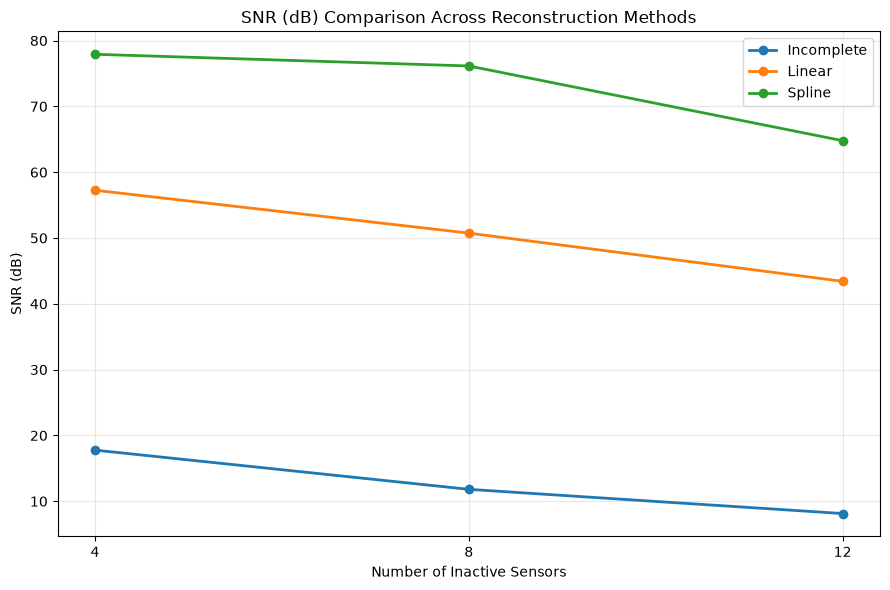

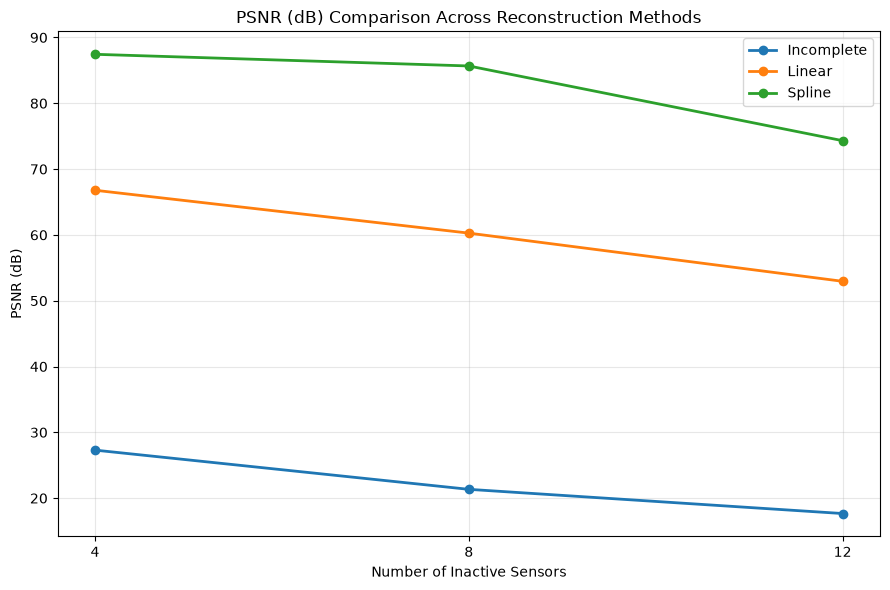

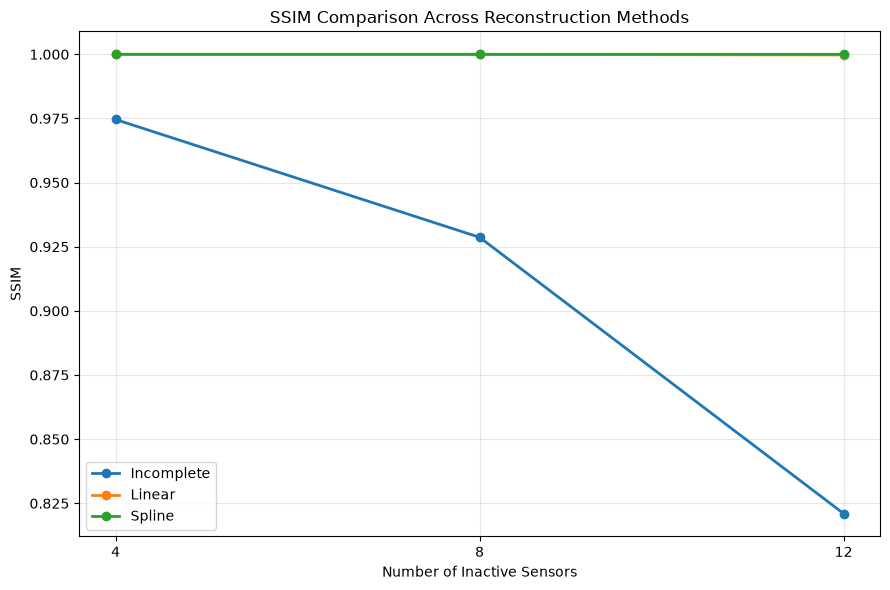

In [6]:
metrics = [
    ("SNR_dB", "SNR (dB)", "day49_snr_comparison.png"),
    ("PSNR_dB", "PSNR (dB)", "day49_psnr_comparison.png"),
    ("SSIM", "SSIM", "day49_ssim_comparison.png")
]

methods = ["Incomplete", "Linear", "Spline"]
x = np.arange(len(dropout_counts))
width = 0.25

for metric_key, metric_label, filename in metrics:
    plt.figure(figsize=(9, 6))

    for j, method in enumerate(methods):
        values = []

        for count in dropout_counts:
            matching = [
                row[metric_key]
                for row in results
                if row["inactive_sensors"] == count
                and row["method"] == method
            ]
            values.append(matching[0])

        plt.plot(
            dropout_counts,
            values,
            marker="o",
            linewidth=2,
            label=method
        )

    plt.xlabel("Number of Inactive Sensors")
    plt.ylabel(metric_label)
    plt.title(f"{metric_label} Comparison Across Reconstruction Methods")
    plt.xticks(dropout_counts)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [7]:
with open(
    OUTPUT_DIR / "day49_quality_metrics_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("Results saved to:", OUTPUT_DIR / "day49_quality_metrics_results.json")
print("All three metric plots saved in:", OUTPUT_DIR.resolve())

Results saved to: ..\outputs\day49_quality_metrics_results.json
All three metric plots saved in: C:\Users\user\OneDrive\Documents\Bachelor_Projects\photoacoustic-sensor-reconstruction\outputs
